# Lab 1: Handle graph data and test a shallow GNN

Credits: pytorch-geometric tutorials
- https://towardsdatascience.com/a-beginners-guide-to-graph-neural-networks-using-pytorch-geometric-part-1-d98dc93e7742/
- https://towardsdatascience.com/a-beginners-guide-to-graph-neural-networks-using-pytorch-geometric-part-2-cd82c01330ab/

We will use **[PyTorch Geometric (PyG) library](https://pytorch-geometric.readthedocs.io/)**.
PyTorch Geometric is an extension library to the popular deep learning framework [PyTorch](https://pytorch.org/), and consists of various methods and utilities to ease the implementation of Graph Neural Networks.

[Additional packages](https://pytorch-geometric.readthedocs.io/en/latest/install/installation.html#additional-libraries) can be installed: `torch_sparse`... Currently, they are not installed in the current `arna-gnn` virtual environment.

Other alternatives:
- [DGL](https://www.dgl.ai/)

**Objectives:** 
- get familiar with graph data using a simple graph-structured example: **Zachary's karate club network**
- get familiar with GNN architecture implementing a simple architecture

##### Load packages

In [44]:
# Helper function for visualization.
%matplotlib inline
import networkx as nx
import matplotlib.pyplot as plt

## Load and inspect the dataset

The [**Zachary's karate club network**](https://en.wikipedia.org/wiki/Zachary%27s_karate_club) describes a **social network** where the *nodes* represent members of a karate club and *relations* the documents links between members who interacted outside the club. Here, we are interested in detecting communities that arise from the member's interaction.

PyG provides an easy access to this dataset through the [`torch_geometric.datasets`](https://pytorch-geometric.readthedocs.io/en/latest/modules/datasets.html#torch_geometric.datasets) subpackage. <br>
You can easily find some metadata attached to it checking the attributes such as `num_features` and `num_classes`.

In [45]:
from torch_geometric.datasets import KarateClub

dataset = KarateClub()
print(f'Dataset: {dataset} is loaded')
print('======================')
print(f'Number of graphs: {len(dataset)}')
print(f'Number of features: {dataset.num_features}')
print(f'Number of classes: {dataset.num_classes}')

Dataset: KarateClub() is loaded
Number of graphs: 1
Number of features: 34
Number of classes: 4


The dataset is composed of a single graph.

In [46]:
len(dataset)

1

The problem is **transductive**, so a `train_mask` is provided along the dataset to be used for the computation of the loss function in the training loop.

In total, only labels of 4 nodes (one for each community) are used for training and the remaining nodes can be used for evaluation.

In [47]:
dataset.train_mask

tensor([ True, False, False, False,  True, False, False, False,  True, False,
        False, False, False, False, False, False, False, False, False, False,
        False, False, False, False,  True, False, False, False, False, False,
        False, False, False, False])

<!--After initializing the [`KarateClub`](https://pytorch-geometric.readthedocs.io/en/latest/modules/datasets.html#torch_geometric.datasets.KarateClub) dataset, we first can inspect some of its properties.
For example, we can see that this dataset holds exactly **one graph**, and that each node in this dataset is assigned a **34-dimensional feature vector** (which uniquely describes the members of the karate club).
Furthermore, the graph holds exactly **4 classes**, which represent the community each node belongs to.
-->
One first step as you usually do with other types of data is characterizing the dataset. Basically, concerning graph, we are interested in the topology of the graph: connectivity, existence of isolated nodes,...

In [48]:
data = dataset[0]  # Get the first graph object.
# Proposition faire une démo pendant le cours et les laisser manipuler ce graphe

print(data)
print('==============================================================')

# Gather some statistics about the graph.
print(f'Number of nodes: {data.num_nodes}')
print(f'Number of edges: {data.num_edges}')
print(f'Average node degree: {data.num_edges / data.num_nodes:.2f}')
print(f'Number of training nodes: {data.train_mask.sum()}')
print(f'Training node label rate: {int(data.train_mask.sum()) / data.num_nodes:.2f}')
print(f'Has isolated nodes: {data.has_isolated_nodes()}')
print(f'Has self-loops: {data.has_self_loops()}')
print(f'Is undirected: {data.is_undirected()}')

Data(x=[34, 34], edge_index=[2, 156], y=[34], train_mask=[34])
Number of nodes: 34
Number of edges: 156
Average node degree: 4.59
Number of training nodes: 4
Training node label rate: 0.12
Has isolated nodes: False
Has self-loops: False
Is undirected: True


Each graph in PyTorch Geometric is represented by a single [`Data`](https://pytorch-geometric.readthedocs.io/en/latest/modules/data.html#torch_geometric.data.Data) object, which holds all the information to describe its graph representation.
We can print the data object anytime via `print(data)` to receive a short summary about its attributes and their shapes:
```
Data(edge_index=[2, 156], x=[34, 34], y=[34], train_mask=[34])
```
We can see that this `data` object holds 4 attributes:
(1) **node features** property as `x` for which each of the 34 nodes is assigned a 34-dim feature vector.<br>
(2) `edge_index` property holds the information about the **graph connectivity**, *i.e.*, a tuple of source and destination node indices for each edge.<br>
(3) **node labels** property as `y` where each node is assigned to exactly one class.<br>
(4) There also exists an additional attribute called `train_mask`, which describes for which nodes we already know their community assigments.

The `data` object also provides some **utility functions** to infer some basic properties of the underlying graph.

For example, we can easily infer whether there exists isolated nodes in the graph (*i.e.* there exists no edge to any node), whether the graph contains self-loops (*i.e.*, $(v, v) \in \mathcal{E}$), or whether the graph is undirected (*i.e.*, for each edge $(v, w) \in \mathcal{E}$ there also exists the edge $(w, v) \in \mathcal{E}$).

The node embedding is an one hot encoder. The number of entries correspond to the total number of members. There are no other feature information.

In [50]:
data.x.shape

torch.Size([34, 34])

In [49]:
data.x

tensor([[1., 0., 0.,  ..., 0., 0., 0.],
        [0., 1., 0.,  ..., 0., 0., 0.],
        [0., 0., 1.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 1., 0., 0.],
        [0., 0., 0.,  ..., 0., 1., 0.],
        [0., 0., 0.,  ..., 0., 0., 1.]])

In [51]:
edge_index = data.edge_index
print(edge_index.t())

tensor([[ 0,  1],
        [ 0,  2],
        [ 0,  3],
        [ 0,  4],
        [ 0,  5],
        [ 0,  6],
        [ 0,  7],
        [ 0,  8],
        [ 0, 10],
        [ 0, 11],
        [ 0, 12],
        [ 0, 13],
        [ 0, 17],
        [ 0, 19],
        [ 0, 21],
        [ 0, 31],
        [ 1,  0],
        [ 1,  2],
        [ 1,  3],
        [ 1,  7],
        [ 1, 13],
        [ 1, 17],
        [ 1, 19],
        [ 1, 21],
        [ 1, 30],
        [ 2,  0],
        [ 2,  1],
        [ 2,  3],
        [ 2,  7],
        [ 2,  8],
        [ 2,  9],
        [ 2, 13],
        [ 2, 27],
        [ 2, 28],
        [ 2, 32],
        [ 3,  0],
        [ 3,  1],
        [ 3,  2],
        [ 3,  7],
        [ 3, 12],
        [ 3, 13],
        [ 4,  0],
        [ 4,  6],
        [ 4, 10],
        [ 5,  0],
        [ 5,  6],
        [ 5, 10],
        [ 5, 16],
        [ 6,  0],
        [ 6,  4],
        [ 6,  5],
        [ 6, 16],
        [ 7,  0],
        [ 7,  1],
        [ 7,  2],
        [ 

We can further visualize the graph by converting it to the `networkx` library format, which implements, in addition to graph manipulation functionalities, powerful tools for visualization:

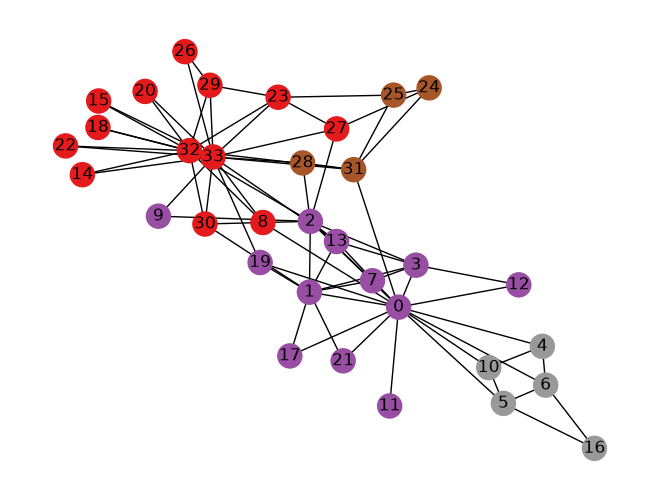

In [10]:
from torch_geometric.utils import to_networkx

G = to_networkx(data, to_undirected=True)
nx.draw(G, with_labels=True, node_color=data.y, cmap=plt.get_cmap('Set1'))

## Implementing Graph Neural Networks

We will use on of the most simple GNN operators, the **GCN layer** ([Kipf et al. (2017)](https://arxiv.org/abs/1609.02907)), which is defined as

$$
\mathbf{x}_v^{(\ell + 1)} = \text{tanh}(\mathbf{W}^{(\ell + 1)} \sum_{w \in \mathcal{N}(v) \, \cup \, \{ v \}} \frac{1}{c_{w,v}} \cdot \mathbf{x}_w^{(\ell)})
$$

where $\mathbf{W}^{(\ell + 1)}$ denotes a trainable weight matrix of shape `[num_output_features, num_input_features]` and $c_{w,v}$ refers to a fixed normalization coefficient for each edge.

PyG implements this layer via [`GCNConv`](https://pytorch-geometric.readthedocs.io/en/latest/modules/nn.html#torch_geometric.nn.conv.GCNConv), which can be executed by passing in the node feature representation `x` and the adjacency list `edge_index`.

Let define our network architecture using `torch.nn.Module` class following this configuration:
- The input dimension of the first layer must correspond to the **number of node features** in the dataset.
- Use **three `GCNConv` layers** with respectively **4, 4 and 2 output features**.
- Apply a **[`tanh`](https://pytorch.org/docs/stable/generated/torch.nn.Tanh.html?highlight=tanh#torch.nn.Tanh) activation** function after each graph convolution layer.
- Add a final **[`Linear`](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Linear.html#torch.nn.Linear) classifier** that maps the 2-dimensional output node embedding to the number of classes in the dataset.
- The `forward()` method should return both the **class predictions** and the **final node embeddings**.

In [ ]:
import torch
from torch.nn import Linear
from torch_geometric.nn import GCNConv


class GCN(torch.nn.Module):
    def __init__(self,num_features=dataset.num_features, num_classes=dataset.num_classes):
        super().__init__()
        torch.manual_seed(1234)
        self.conv1 = GCNConv(num_features, 4)
        self.conv2 = GCNConv(4, 4)
        self.conv3 = GCNConv(4, 2)
        self.classifier = Linear(2, num_classes)

    def forward(self, x, edge_index):
        h = self.conv1(x, edge_index)
        h = h.tanh()
        h = self.conv2(h, edge_index)
        h = h.tanh()
        h = self.conv3(h, edge_index)
        h = h.tanh()  # Final GNN embedding space.

        # Apply a final (linear) classifier.
        out = self.classifier(h)

        return out, h

### Training on the Karate Club Network

Training our model is very similar to any other PyTorch model.

In addition to defining our network architecture, we define a loss criterion (here, [`CrossEntropyLoss`](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)) and an optimizer (here, [`Adam`](https://pytorch.org/docs/stable/optim.html?highlight=adam#torch.optim.Adam)).

The transductive learning scenario is achieved by the following line:
```
loss = criterion(out[data.train_mask], data.y[data.train_mask])
```
While we compute node embeddings for all of our nodes, we **only make use of the training nodes for computing the loss**.

In [ ]:
import time
import torch.nn.functional as F

In [ ]:
criterion = torch.nn.CrossEntropyLoss()  
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)

def train(model, data, optimizer, criterion, epochs=200, verbose=True):
    t0 = time.time()

    for epoch in range(epochs + 1):
        
        model.train()  # Mode entraînement
        optimizer.zero_grad()  # Reset des gradients
        out,_ = model(data.x, data.edge_index)  # Forward
        loss = criterion(out[data.train_mask], data.y[data.train_mask])  # Perte
        loss.backward()
        optimizer.step()
        
        # Évaluation sur le jeu d'entraînement et de test
        model.eval()
        with torch.no_grad():
            out,_ = model(data.x, data.edge_index)
            pred = F.softmax(out).argmax(dim=1)
            acc_train = (pred[data.train_mask] == data.y[data.train_mask]).sum() / data.train_mask.sum()
            acc_test = (pred[~data.train_mask] == data.y[~data.train_mask]).sum() / (~data.train_mask).sum()

        if verbose and epoch % 20 == 0:
            print(f"Époque {epoch:03d} | Loss: {loss:.4f} | Accuracy train: {acc_train:.4f} | Accuracy test: {acc_test:.4f}")

    print(f"Entraînement terminé en {time.time() - t0:.2f}s")
    return model

In [ ]:
model = GCN(dataset.num_features, dataset.num_classes)
model = train(model, data, optimizer, criterion, epochs=100)

Époque 000 | Loss: 1.4268 | Accuracy train: 0.3529 | Accuracy test: 0.3529
Époque 020 | Loss: 1.4268 | Accuracy train: 0.3529 | Accuracy test: 0.3529
Époque 040 | Loss: 1.4268 | Accuracy train: 0.3529 | Accuracy test: 0.3529
Époque 060 | Loss: 1.4268 | Accuracy train: 0.3529 | Accuracy test: 0.3529
Époque 080 | Loss: 1.4268 | Accuracy train: 0.3529 | Accuracy test: 0.3529
Époque 100 | Loss: 1.4268 | Accuracy train: 0.3529 | Accuracy test: 0.3529
Entraînement terminé en 0.14s


/var/folders/gz/fvbll7yj3bv9x3w1xh6s9zvm0000gn/T/ipykernel_45177/977540601.py:24: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  pred = F.softmax(out).argmax(dim=1)


A difference will be observed if the training accuracy is calculated in `train` mode.

#### Define a training and test sets manually

In [32]:
# Define the number of nodes and classes
num_nodes = data.num_nodes
num_classes = len(data.y.unique())

# Split the nodes into train and test sets
# For example, we can use 50% for training and 50% for testing
train_mask = torch.zeros(num_nodes, dtype=torch.bool)
test_mask = torch.zeros(num_nodes, dtype=torch.bool)

# Randomly select 50% of the nodes for training
train_indices = torch.randperm(num_nodes)[:num_nodes // 2]
test_indices = torch.randperm(num_nodes)[num_nodes // 2:]

train_mask[train_indices] = True
test_mask[test_indices] = True

# Assign the masks to the data object
data.train_mask = train_mask
data.test_mask = test_mask

# Now you can use data.train_mask and data.test_mask during training and testing
print(f"Training nodes: {train_indices}")
print(f"Test nodes: {test_indices}")


Training nodes: tensor([22,  6, 21, 31,  1, 14, 17, 16,  0,  2, 29, 33, 30, 18,  3, 20,  5])
Test nodes: tensor([ 6,  5, 25, 21, 10, 20, 33, 30,  4,  2, 16, 19,  8, 32,  3, 24,  1])
